In [1]:
'''Design and implement a simple yet intuitive user interface using Streamlit or Gradio for seamless model 
input handling,predictions visualization, and end-user interaction for both batch and real-time use cases.'''

'Design and implement a simple yet intuitive user interface using Streamlit or Gradio for seamless model \ninput handling,predictions visualization, and end-user interaction for both batch and real-time use cases.'

In [2]:
# load dataset and inspect summary statistics
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.preprocessing import LabelEncoder
import joblib

df = pd.read_csv("global_pharmacy_sales_data.csv")
print("dataset shape:", df.shape)
print(df[['date', 'region', 'category', 'medicine', 'units_sold', 'unit_price', 'stock_level']].head(3))
print(df.describe())


dataset shape: (177990, 14)
         date       region category    medicine  units_sold  unit_price  \
0  2025-10-12  Middle East  Chronic  Amlodipine         328       45.38   
1  2020-09-15   South Asia  Chronic  Amlodipine         371       75.49   
2  2020-02-26  Middle East  Vitamin   Vitamin C         948       22.51   

   stock_level  
0         4774  
1         4584  
2         3934  
                year          month            day     units_sold  \
count  177990.000000  177990.000000  177990.000000  177990.000000   
mean     2022.499702       6.521754      15.730457     447.913849   
std         1.708113       3.448703       8.801170     338.924528   
min      2020.000000       1.000000       1.000000      31.000000   
25%      2021.000000       4.000000       8.000000     284.000000   
50%      2023.000000       7.000000      16.000000     387.000000   
75%      2024.000000      10.000000      23.000000     529.000000   
max      2025.000000      12.000000      31.000000 

In [3]:
# prepare features and train sales regressor with evaluation
features = ['category', 'medicine', 'age_group', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']
data = df[features + ['units_sold']].dropna()

encoders = {}
for col in ['category', 'medicine', 'age_group']:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    encoders[col] = le

X = data[features]
y = data['units_sold']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(n_estimators=60, max_depth=10, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
print(f"model performance - r2: {r2:.4f}, mae: {mae:.2f}")

joblib.dump(model, "sales_model.pkl")
joblib.dump(encoders, "encoders.pkl")
joblib.dump(features, "features.pkl")
print("model artifacts saved successfully")


model performance - r2: 0.9244, mae: 73.65
model artifacts saved successfully


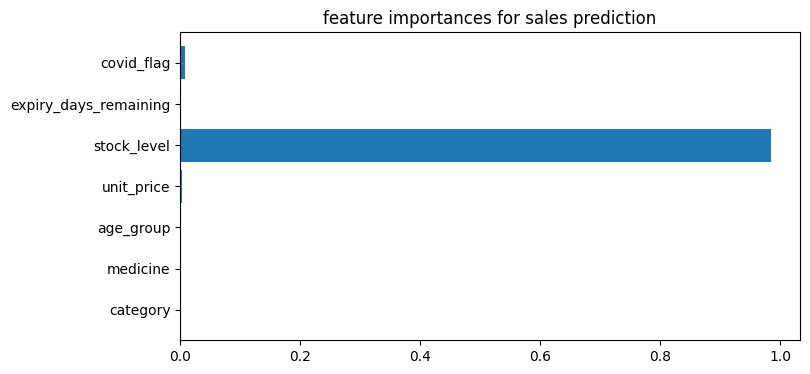

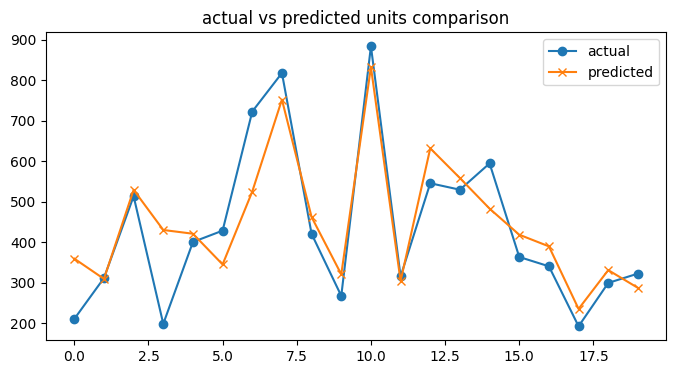

In [4]:
# plot feature importances and prediction error comparison
importances = model.feature_importances_
plt.figure(figsize=(8, 4))
plt.barh(features, importances)
plt.title("feature importances for sales prediction")
plt.show()

sample_actual = y_test.iloc[:20].values
sample_predicted = y_pred[:20]
plt.figure(figsize=(8, 4))
plt.plot(sample_actual, label='actual', marker='o')
plt.plot(sample_predicted, label='predicted', marker='x')
plt.title("actual vs predicted units comparison")
plt.legend()
plt.show()


In [5]:
# test real time scenario predictions and batch scoring
scenario_normal = pd.DataFrame([{
    'category': encoders['category'].transform(['Chronic'])[0],
    'medicine': encoders['medicine'].transform(['Metformin'])[0],
    'age_group': encoders['age_group'].transform(['26-45'])[0],
    'unit_price': 50.0,
    'stock_level': 4500,
    'expiry_days_remaining': 365,
    'covid_flag': 0
}])
scenario_covid = scenario_normal.copy()
scenario_covid['covid_flag'] = 1

pred_normal = model.predict(scenario_normal)[0]
pred_covid = model.predict(scenario_covid)[0]
print(f"normal demand: {pred_normal:.1f} units | covid surge demand: {pred_covid:.1f} units")

batch_test = X_test.iloc[:10].copy()
batch_test['actual_units'] = y_test.iloc[:10].values
batch_test['predicted_units'] = model.predict(batch_test[features]).round(2)
batch_test['projected_revenue'] = (batch_test['predicted_units'] * batch_test['unit_price']).round(2)
print(batch_test[['unit_price', 'actual_units', 'predicted_units', 'projected_revenue']].head())


normal demand: 431.9 units | covid surge demand: 486.6 units
        unit_price  actual_units  predicted_units  projected_revenue
168929       53.07           211           359.94           19102.02
20669        79.53           312           309.93           24648.73
4526         49.82           514           529.73           26391.15
171149       64.46           199           430.64           27759.05
65989        87.59           401           421.40           36910.43


In [6]:
# build comprehensive streamlit app with batch and real time handling
app_code = '''import streamlit as st
import pandas as pd
import numpy as np
import joblib

st.set_page_config(page_title="Pharmacy Demand Predictor", layout="wide")
st.title("Pharmacy Sales Prediction & Demand Planning")

@st.cache_resource
def load_model_suite():
    model = joblib.load("sales_model.pkl")
    encoders = joblib.load("encoders.pkl")
    features = joblib.load("features.pkl")
    df = pd.read_csv("global_pharmacy_sales_data.csv")
    return model, encoders, features, df

model, encoders, features, df = load_model_suite()

tabs = st.tabs(["Real-Time Prediction", "Batch Prediction & Analysis", "Model Performance & Insights"])

with tabs[0]:
    st.subheader("Single Medicine Demand Forecaster")
    col1, col2, col3 = st.columns(3)
    with col1:
        category = st.selectbox("Category", encoders['category'].classes_)
        medicine = st.selectbox("Medicine", encoders['medicine'].classes_)
        age_group = st.selectbox("Age Group", encoders['age_group'].classes_)
    with col2:
        unit_price = st.number_input("Unit Price ($)", min_value=1.0, max_value=500.0, value=50.0, step=1.0)
        stock_level = st.number_input("Current Stock Level", min_value=1, max_value=20000, value=4000, step=50)
    with col3:
        expiry_days = st.slider("Expiry Days Remaining", 30, 730, 365)
        covid_flag = st.selectbox("COVID Outbreak Surge Flag", [0, 1], format_func=lambda x: "Yes" if x == 1 else "No")
    
    if st.button("Forecast Demand", key="rt_btn"):
        row = pd.DataFrame([{
            'category': encoders['category'].transform([category])[0],
            'medicine': encoders['medicine'].transform([medicine])[0],
            'age_group': encoders['age_group'].transform([age_group])[0],
            'unit_price': unit_price,
            'stock_level': stock_level,
            'expiry_days_remaining': expiry_days,
            'covid_flag': covid_flag
        }])
        pred_units = model.predict(row)[0]
        est_revenue = pred_units * unit_price
        
        mcol1, mcol2, mcol3 = st.columns(3)
        mcol1.metric("Predicted Units Sold", f"{pred_units:.1f}")
        mcol2.metric("Projected Revenue", f"${est_revenue:,.2f}")
        stock_coverage = "Adequate Stock" if stock_level >= pred_units else "Stock-out Warning!"
        mcol3.metric("Inventory Status", stock_coverage)
        if stock_level < pred_units:
            st.warning(f"Reorder Recommended: Demand ({pred_units:.1f}) exceeds available inventory ({stock_level}).")

with tabs[1]:
    st.subheader("Batch Prediction Workflow")
    sample_csv = df[features].head(10).to_csv(index=False).encode('utf-8')
    st.download_button("Download Sample Batch Template", sample_csv, "sample_batch_template.csv", "text/csv")
    
    uploaded_file = st.file_uploader("Upload CSV for Batch Prediction", type=["csv"])
    if uploaded_file is not None:
        batch_df = pd.read_csv(uploaded_file)
        st.write("Uploaded Records Preview:", batch_df.head())
        if st.button("Run Batch Forecast"):
            work_df = batch_df.copy()
            for col in ['category', 'medicine', 'age_group']:
                if col in work_df.columns:
                    work_df[col] = encoders[col].transform(work_df[col].astype(str))
            batch_df['predicted_units_sold'] = model.predict(work_df[features]).round(2)
            if 'unit_price' in batch_df.columns:
                batch_df['projected_revenue'] = (batch_df['predicted_units_sold'] * batch_df['unit_price']).round(2)
            
            b1, b2, b3 = st.columns(3)
            b1.metric("Total Batch Records", len(batch_df))
            b2.metric("Total Predicted Units", f"{batch_df['predicted_units_sold'].sum():,.1f}")
            if 'projected_revenue' in batch_df.columns:
                b3.metric("Total Projected Revenue", f"${batch_df['projected_revenue'].sum():,.2f}")
            
            st.write("Prediction Results:", batch_df.head(10))
            st.bar_chart(batch_df['predicted_units_sold'].head(20))
            
            csv_result = batch_df.to_csv(index=False).encode('utf-8')
            st.download_button("Download Forecasted CSV", csv_result, "batch_forecast_results.csv", "text/csv")

with tabs[2]:
    st.subheader("Model Performance & Feature Importance")
    importances = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
    st.write("### Feature Importance Ranking")
    st.bar_chart(importances)
'''

with open("app.py", "w") as f:
    f.write(app_code.strip())
print("app.py successfully created with real time and batch features")


app.py successfully created with real time and batch features


In [7]:
# display instructions to launch the user interface
print("run 'streamlit run app.py' in terminal to launch the interface")


run 'streamlit run app.py' in terminal to launch the interface
